# comets Demo: Kuramoto n=2 coupled oscillator → CoMET vs PCA/UMAP/CEBRA


In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA

from pathlib import Path
import sys

for p in [Path.cwd().resolve(), *Path.cwd().resolve().parents]:
    code_dir = p / "code"
    if (code_dir / "comets").exists():
        if str(code_dir) not in sys.path:
            sys.path.insert(0, str(code_dir))
        break

import comets
from comets.encoders import Conv1DEncoder, Conv1DEncoderConfig, SkippedConvEncoder, SkippedConvEncoderConfig, CEBRASKipEncoder
from comets.configs import ModalityConfig, SamplingConfig, TrainingConfig
from comets.heads import TwoLayerMLP, LinearHead, IdentityHead, OneLayerMLP


import umap
import cebra
import torch

In [2]:
# =====================================================
# Kuramoto coupled oscillators (theta–gamma style)
# =====================================================


# -------------------------
# Parameters
# -------------------------
T = 2000                 # total samples
in_chA, in_chB = 16, 8    # informative channels per view
confA, confB = 4, 2       # confounding channels per view
noise = 1.0               # output noise scale in nonlinear mixers

# Kuramoto dynamics
f1 = 0.04                 # base angular increment (rad/step) for oscillator 1 (slow)
f2 = 0.37                 # base angular increment (rad/step) for oscillator 2 (fast)
K12 = 0.06                # coupling from 2 -> 1
K21 = 0.04                # coupling from 1 -> 2 (asymmetric but small)
sigma1 = 0.01             # phase noise std for osc 1
sigma2 = 0.01             # phase noise std for osc 2

# Cross-modal lag (samples) applied to modality B only
lag_B = 0

# -------------------------
# Latent phases via Euler updates
# -------------------------
rng = np.random.default_rng(42)
theta1 = np.zeros(T, dtype=np.float32)
theta2 = np.zeros(T, dtype=np.float32)

# random initial phases
theta1[0] = 2*np.pi*rng.random()
theta2[0] = 2*np.pi*rng.random()

# Euler integration of coupled phase dynamics
for t in range(T - 1):
    dtheta1 = f1 + K12 * np.sin(theta2[t] - theta1[t]) + sigma1 * rng.standard_normal()
    dtheta2 = f2 + K21 * np.sin(theta1[t] - theta2[t]) + sigma2 * rng.standard_normal()
    theta1[t+1] = (theta1[t] + dtheta1).astype(np.float32)
    theta2[t+1] = (theta2[t] + dtheta2).astype(np.float32)

# wrap to [0, 2π)
theta1 = np.mod(theta1, 2*np.pi).astype(np.float32)
theta2 = np.mod(theta2, 2*np.pi).astype(np.float32)

# -------------------------
# Latent feature basis
# -------------------------
# Use harmonics to give mixers something nonlinear to pick up
# baseA emphasizes slow oscillator; baseB will use lagged phases
baseA = np.stack(
    [np.sin(theta1), np.cos(theta1),
     np.sin(theta2), np.cos(theta2)], axis=1
).astype(np.float32)  # [T,4]

# apply fixed lag to modality B's phases (circular shift)
theta1_B = np.roll(theta1, lag_B)
theta2_B = np.roll(theta2, lag_B)
baseB = np.stack(
    [np.sin(theta1_B), np.cos(theta1_B),
     np.sin(2*theta2_B), np.cos(2*theta2_B)], axis=1
).astype(np.float32)  # [T,4]

# -------------------------
# Nonlinear mixing
# -------------------------
def nonlinear_mix(base, W, nonlin="tanh", noise=0.05, rng=None):
    X = base @ W
    if nonlin == "tanh":
        X = np.tanh(X)
    elif nonlin == "sin":
        X = np.sin(X)
    elif nonlin == "relu":
        X = np.maximum(0, X)
    elif nonlin == "softsign":
        X = X / (1.0 + np.abs(X))
    if rng is None:
        rng = np.random.default_rng()
    return X + noise * rng.standard_normal(X.shape)

# -------------------------
# Informative channels
# -------------------------
W_A = rng.standard_normal((4, in_chA)).astype(np.float32)
W_B = rng.standard_normal((4, in_chB)).astype(np.float32)

mixA = nonlinear_mix(baseA, W_A, nonlin="tanh",    noise=noise, rng=rng)
mixB = nonlinear_mix(baseB, W_B, nonlin="softsign", noise=noise, rng=rng)

# -------------------------
# Confounding channels
# -------------------------
# white noise confounds
confA_white = rng.standard_normal((T, confA)).astype(np.float32)
confB_white = rng.standard_normal((T, confB)).astype(np.float32)

# slow drift confounds (different slow rates per view)
t = np.arange(T, dtype=np.float32)
confA_drift = (np.sin(0.0006 * t)[:, None] * rng.standard_normal((1, confA))).astype(np.float32)
confB_drift = (np.cos(0.0008 * t)[:, None] * rng.standard_normal((1, confB))).astype(np.float32)

mixA = np.concatenate([mixA, confA_white, confA_drift], axis=1)
mixB = np.concatenate([mixB, confB_white, confB_drift], axis=1)

# -------------------------
# Random subsampling (simulate dropouts)
# -------------------------
keep_mask = rng.choice([0, 1], size=T, p=[0.1,0.9])  # keep ~40% like your torus snippet
keep_idx = np.sort(np.where(keep_mask == 1)[0])       # preserve temporal order

mixA = mixA[keep_idx]
mixB = mixB[keep_idx]
theta1, theta2 = theta1[keep_idx], theta2[keep_idx]

# -------------------------
# Convert to torch
# -------------------------
A = torch.tensor(mixA, dtype=torch.float32)
B = torch.tensor(mixB, dtype=torch.float32)

# -------------------------
# Quick check
# -------------------------
print(f"A: {A.shape}, B: {B.shape}")
print(f"θ1, θ2 shapes: {theta1.shape}, {theta2.shape}")


A: torch.Size([1821, 24]), B: torch.Size([1821, 12])
θ1, θ2 shapes: (1821,), (1821,)


In [3]:
# modality configs
modA = ModalityConfig(
    encoder_cls=CEBRASKipEncoder,
    encoder_cfg=SkippedConvEncoderConfig(in_channels=A.shape[1], emb_dim=32),
    win_len=10
)
modB = ModalityConfig(
    encoder_cls=CEBRASKipEncoder,
    encoder_cfg=SkippedConvEncoderConfig(in_channels=B.shape[1], emb_dim=32),
    win_len=10
)

sampling = SamplingConfig(
    batch_size=256,
    pos_offset=1,
    # negative_mask_dist=10   # e.g., mask negatives within ±10 timepoints
)

train_cfg = TrainingConfig(epochs=500,lr=1e-3,temperature= 0.1,proj_dim=8,
    alpha_cross=0.5,  # weight cross vs within
    beta=0.5,         # balance A vs B (default equal)
    head_cls=IdentityHead)

In [4]:
model = comets.train(A, modA, B, modB, sampling, train_cfg)

Training: 100%|██████████| 500/500 [01:30<00:00,  5.51it/s, total=0.5295, within=0.6806, cross=0.3785, lr=0.00e+00]


In [5]:

ZA = model.embedA(A)
ZB = model.embedB(B)
print("ZA:", ZA.shape, "ZB:", ZB.shape)

ZA: (1821, 32) ZB: (1821, 32)


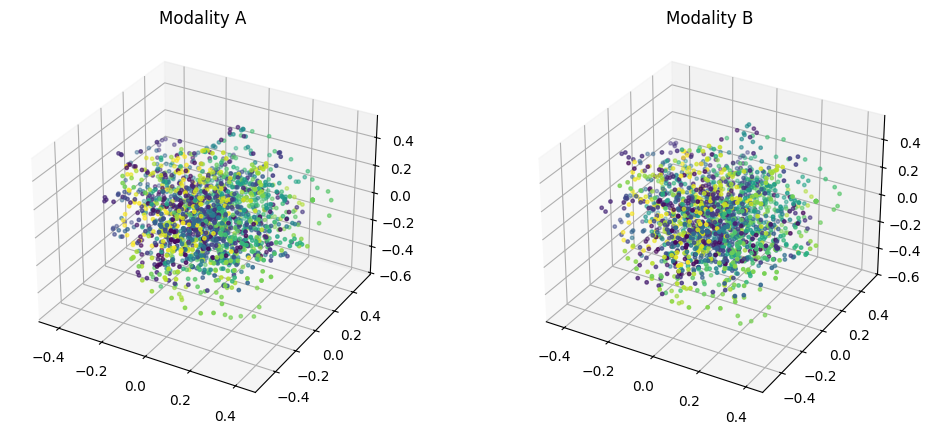

In [6]:
# 5) Visualize embeddings with our built-in viz
comets.plotemb2(
    ZA, ZB,
    color=theta1,               # color points by latent angle
    titles=("Modality A", "Modality B"),
    mode="direct",                 # project to 3D PCA for plotting
    dims=[2,3,5]
)

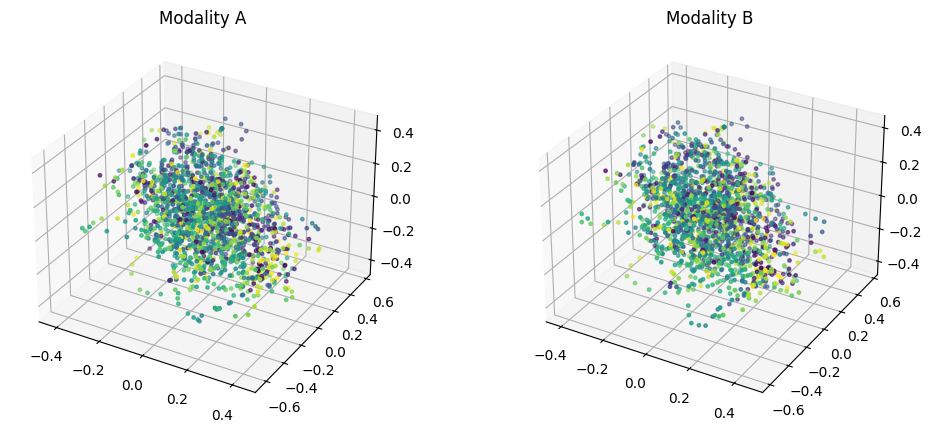

In [7]:
# 5) Visualize embeddings with our built-in viz
comets.plotemb2(
    ZA, ZB,
    color=theta2,               # color points by latent angle
    titles=("Modality A", "Modality B"),
    mode="direct"                  # project to 3D PCA for plotting
)

In [8]:
# 3) Baselines: PCA, UMAP (on each view separately)
# PCA and UMAP baselines
Z1_pca = PCA(n_components=3).fit_transform(A)
Z2_pca = PCA(n_components=3).fit_transform(B)


reducer = umap.UMAP(n_components=3, n_neighbors=15, min_dist=0.1, random_state=0)
Z1_umap = reducer.fit_transform(A)
Z2_umap = reducer.fit_transform(B)


f:\anaconda\envs\NRMNFD\lib\site-packages\sklearn\utils\deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(
f:\anaconda\envs\NRMNFD\lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
f:\anaconda\envs\NRMNFD\lib\site-packages\sklearn\utils\deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(


In [9]:
# Optional: CEBRA baseline
cebra_temp = 1

modelA_cebra = cebra.CEBRA(model_architecture='offset10-model',max_iterations=500,
                            batch_size=256, temperature=cebra_temp, verbose = True)
ZA_cebra = modelA_cebra.fit_transform(A)

modelB_cebra = cebra.CEBRA(model_architecture='offset10-model',max_iterations=500,
                            batch_size=256, temperature=cebra_temp, verbose = True)
ZB_cebra = modelB_cebra.fit_transform(B)

  0%|          | 0/500 [00:00<?, ?it/s]

pos: -0.9644 neg:  5.6469 total:  4.6824 temperature:  1.0000: 100%|██████████| 500/500 [00:07<00:00, 66.54it/s]
pos: -0.9367 neg:  5.6478 total:  4.7112 temperature:  1.0000: 100%|██████████| 500/500 [00:06<00:00, 71.72it/s]


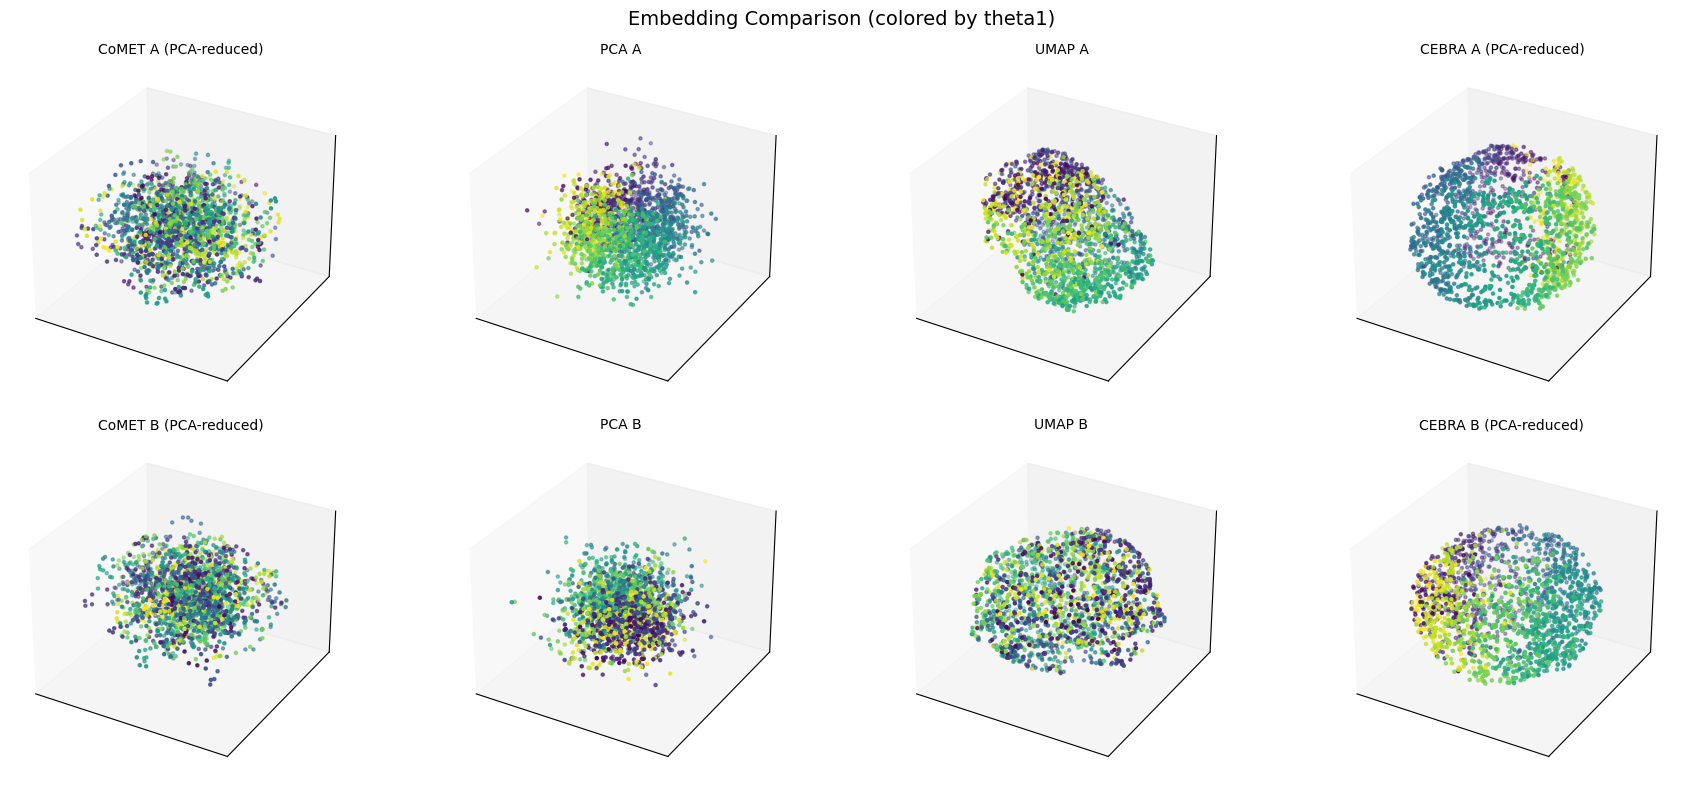

In [10]:
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D  # noqa
from sklearn.decomposition import PCA
import numpy as np

# assume you already have:
# ZA, ZB (CoMET)
# ZA_cebra, ZB_cebra (CEBRA)
# Z1_pca, Z2_pca (PCA)
# Z1_umap, Z2_umap (UMAP)
# theta1 (color variable)

def reduce3(Z):
    """Return a 3-D PCA projection regardless of input dim."""
    Z = np.asarray(Z)
    if Z.shape[1] > 3:
        Z = PCA(n_components=3).fit_transform(Z)
    elif Z.shape[1] < 3:
        pad = np.zeros((Z.shape[0], 3 - Z.shape[1]))
        Z = np.concatenate([Z, pad], axis=1)
    return Z[:, 0], Z[:, 1], Z[:, 2]

# ------------------------------------------
# Create figure: 2 rows x 4 columns
# ------------------------------------------
fig = plt.figure(figsize=(18, 8))

titles_top = ["CoMET A (PCA-reduced)", "PCA A", "UMAP A", "CEBRA A (PCA-reduced)"]
titles_bot = ["CoMET B (PCA-reduced)", "PCA B", "UMAP B", "CEBRA B (PCA-reduced)"]

# Apply PCA to CoMET / CEBRA before plotting
ZA_red = PCA(n_components=3).fit_transform(ZA)
ZB_red = PCA(n_components=3).fit_transform(ZB)
ZA_cebra_red = PCA(n_components=3).fit_transform(ZA_cebra)
ZB_cebra_red = PCA(n_components=3).fit_transform(ZB_cebra)

datasets_top = [ZA_red, Z1_pca, Z1_umap, ZA_cebra_red]
datasets_bot = [ZB_red, Z2_pca, Z2_umap, ZB_cebra_red]

for i in range(4):
    # ---- Top row (view A) ----
    ax = fig.add_subplot(2, 4, i + 1, projection='3d')
    X, Y, Z = reduce3(datasets_top[i])
    ax.scatter(X, Y, Z, c=theta1, cmap='viridis', s=5)
    ax.set_title(titles_top[i], fontsize=10)
    ax.set_xticks([]); ax.set_yticks([]); ax.set_zticks([])

    # ---- Bottom row (view B) ----
    ax = fig.add_subplot(2, 4, i + 5, projection='3d')
    X, Y, Z = reduce3(datasets_bot[i])
    ax.scatter(X, Y, Z, c=theta1, cmap='viridis', s=5)
    ax.set_title(titles_bot[i], fontsize=10)
    ax.set_xticks([]); ax.set_yticks([]); ax.set_zticks([])

fig.suptitle("Embedding Comparison (colored by theta1)", fontsize=14)
plt.tight_layout()
plt.show()


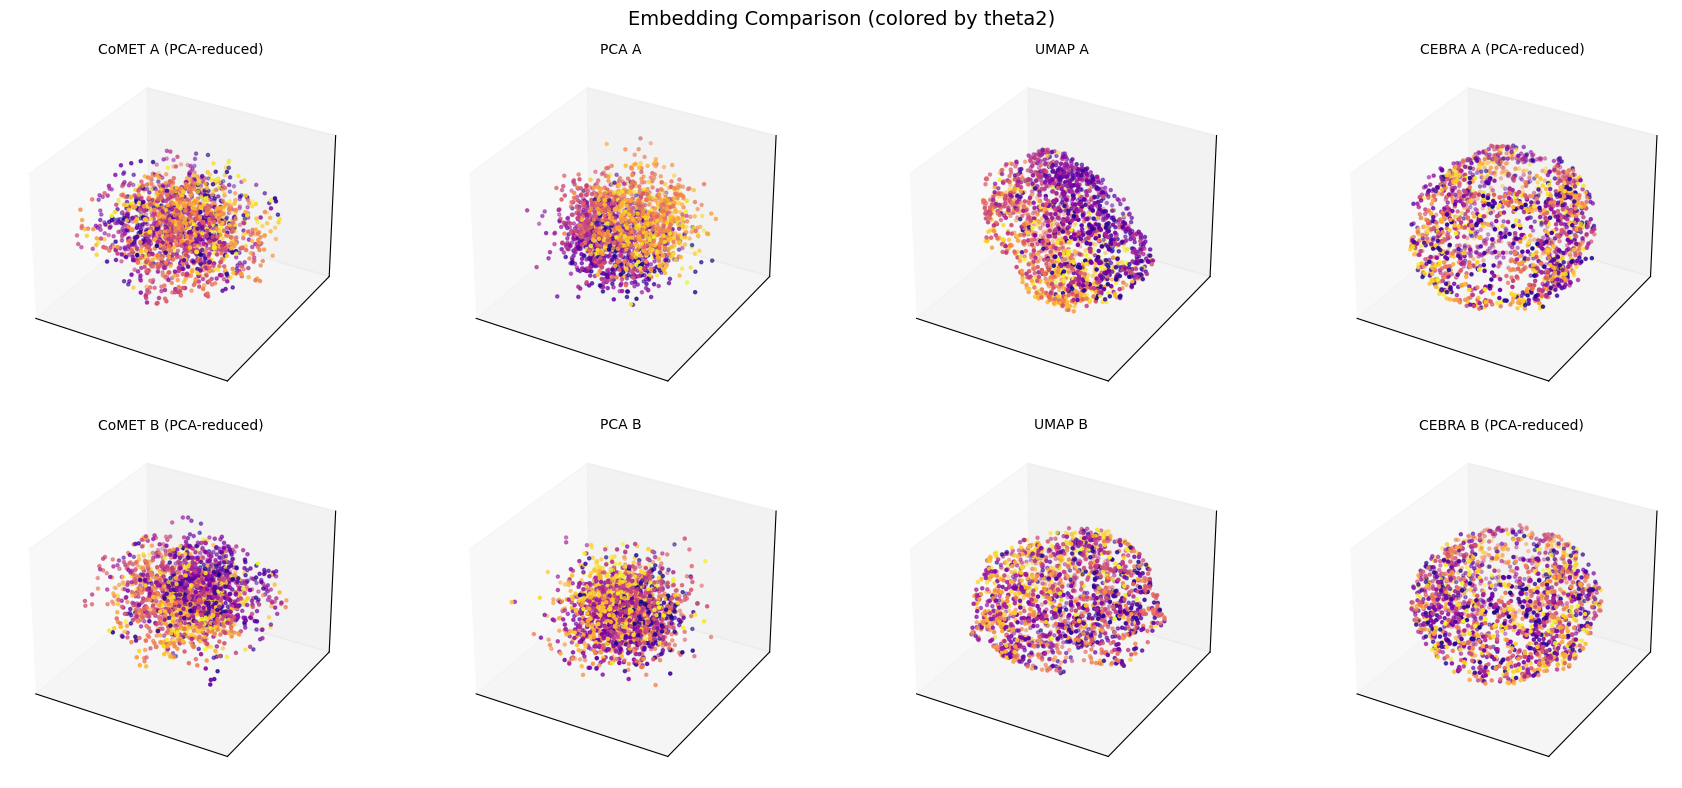

In [11]:
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D  # noqa
from sklearn.decomposition import PCA
import numpy as np

# assume you already have:
# ZA, ZB (CoMET)
# ZA_cebra, ZB_cebra (CEBRA)
# Z1_pca, Z2_pca (PCA)
# Z1_umap, Z2_umap (UMAP)
# theta1 (color variable)

def reduce3(Z):
    """Return a 3-D PCA projection regardless of input dim."""
    Z = np.asarray(Z)
    if Z.shape[1] > 3:
        Z = PCA(n_components=3).fit_transform(Z)
    elif Z.shape[1] < 3:
        pad = np.zeros((Z.shape[0], 3 - Z.shape[1]))
        Z = np.concatenate([Z, pad], axis=1)
    return Z[:, 0], Z[:, 1], Z[:, 2]

# ------------------------------------------
# Create figure: 2 rows x 4 columns
# ------------------------------------------
fig = plt.figure(figsize=(18, 8))

titles_top = ["CoMET A (PCA-reduced)", "PCA A", "UMAP A", "CEBRA A (PCA-reduced)"]
titles_bot = ["CoMET B (PCA-reduced)", "PCA B", "UMAP B", "CEBRA B (PCA-reduced)"]

# Apply PCA to CoMET / CEBRA before plotting
ZA_red = PCA(n_components=3).fit_transform(ZA)
ZB_red = PCA(n_components=3).fit_transform(ZB)
ZA_cebra_red = PCA(n_components=3).fit_transform(ZA_cebra)
ZB_cebra_red = PCA(n_components=3).fit_transform(ZB_cebra)

datasets_top = [ZA_red, Z1_pca, Z1_umap, ZA_cebra_red]
datasets_bot = [ZB_red, Z2_pca, Z2_umap, ZB_cebra_red]

for i in range(4):
    # ---- Top row (view A) ----
    ax = fig.add_subplot(2, 4, i + 1, projection='3d')
    X, Y, Z = reduce3(datasets_top[i])
    ax.scatter(X, Y, Z, c=theta2, cmap='plasma', s=5)
    ax.set_title(titles_top[i], fontsize=10)
    ax.set_xticks([]); ax.set_yticks([]); ax.set_zticks([])

    # ---- Bottom row (view B) ----
    ax = fig.add_subplot(2, 4, i + 5, projection='3d')
    X, Y, Z = reduce3(datasets_bot[i])
    ax.scatter(X, Y, Z, c=theta2,cmap='plasma', s=5)
    ax.set_title(titles_bot[i], fontsize=10)
    ax.set_xticks([]); ax.set_yticks([]); ax.set_zticks([])

fig.suptitle("Embedding Comparison (colored by theta2)", fontsize=14)
plt.tight_layout()
plt.show()


In [12]:
# 6) Decoding: predict latent angles from embeddings
# We'll use Ridge regression to predict sin/cos of angle for circular decoding,
# then compute mean R^2 on sin and cos.

from sklearn.linear_model import Ridge
from sklearn.metrics import r2_score

In [13]:

def circular_decode_score(Z, ang):
    Z = np.asarray(Z)
    y = np.stack([np.sin(ang), np.cos(ang)], axis=1)
    n = len(ang)
    ntr = int(0.7 * n)
    Xtr, Xte = Z[:ntr], Z[ntr:]
    ytr, yte = y[:ntr], y[ntr:]
    model = Ridge(alpha=1.0)
    model.fit(Xtr, ytr)
    yhat = model.predict(Xte)
    r2_sin = r2_score(yte[:, 0], yhat[:, 0])
    r2_cos = r2_score(yte[:, 1], yhat[:, 1])
    return (r2_sin + r2_cos) / 2

scores = {}
toval = theta1
scores['CoMETs_A'] = circular_decode_score(ZA, toval)
scores['CoMETs_B'] = circular_decode_score(ZB, toval)
scores['PCA_A']   = circular_decode_score(Z1_pca, toval)
scores['PCA_B']   = circular_decode_score(Z2_pca, toval)
scores['UMAP_A']  = circular_decode_score(Z1_umap, toval)
scores['UMAP_B']  = circular_decode_score(Z2_umap, toval)
scores['CEBRA_A'] = circular_decode_score(ZA_cebra, toval)
scores['CEBRA_B'] = circular_decode_score(ZB_cebra, toval)

print("Decoding scores (mean R2 on sin/cos):")
for k, v in scores.items():
    print(f"{k:10s}: {v:.3f}")


Decoding scores (mean R2 on sin/cos):
CoMETs_A  : 0.825
CoMETs_B  : 0.805
PCA_A     : 0.619
PCA_B     : 0.209
UMAP_A    : 0.611
UMAP_B    : 0.185
CEBRA_A   : 0.875
CEBRA_B   : 0.696


In [ ]:

def circular_decode_score(Z, ang):
    Z = np.asarray(Z)
    y = np.stack([np.sin(ang), np.cos(ang)], axis=1)
    n = len(ang)
    ntr = int(0.7 * n)
    Xtr, Xte = Z[:ntr], Z[ntr:]
    ytr, yte = y[:ntr], y[ntr:]
    model = Ridge(alpha=1.0)
    model.fit(Xtr, ytr)
    yhat = model.predict(Xte)
    r2_sin = r2_score(yte[:, 0], yhat[:, 0])
    r2_cos = r2_score(yte[:, 1], yhat[:, 1])
    return (r2_sin + r2_cos) / 2

scores = {}
toval = theta2
scores['CoMETs_A'] = circular_decode_score(ZA, toval)
scores['CoMETs_B'] = circular_decode_score(ZB, toval)
scores['PCA_A']   = circular_decode_score(Z1_pca, toval)
scores['PCA_B']   = circular_decode_score(Z2_pca, toval)
scores['UMAP_A']  = circular_decode_score(Z1_umap, toval)
scores['UMAP_B']  = circular_decode_score(Z2_umap, toval)
scores['CEBRA_A'] = circular_decode_score(ZA_cebra, toval)
scores['CEBRA_B'] = circular_decode_score(ZB_cebra, toval)

print("Decoding scores (mean R2 on sin/cos):")
for k, v in scores.items():
    print(f"{k:10s}: {v:.3f}")


Decoding scores (mean R2 on sin/cos):
CoMETs_A  : 0.348
CoMETs_B  : 0.293
PCA_A     : 0.331
PCA_B     : 0.006
UMAP_A    : 0.278
UMAP_B    : 0.010
CEBRA_A   : 0.806
CEBRA_B   : -0.003


: 